# 06 The final exam, and the ranking

The test part hasn't been used yet. I score the forest on it once, next to the baseline and the guess by share,
rank the 8 defects from hardest to easiest, and look at what it gets wrong. If something has to change, it changes
in 05 on validation, not here.

Saves `output/test_predictions.npz`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score

import wafer

f = np.load("output/features.npz")
X_test, y_test, y_train = f["X_test"], f["y_test"], f["y_train"] # first time the test part gets used
maps_test = np.load("output/split.npz")["maps_test"]

forest = joblib.load("output/forest.joblib")
baseline = joblib.load("output/baseline.joblib")

y_pred = forest.predict(X_test)
y_base = baseline.predict(X_test)
# same guess by share as in 04
rng = np.random.default_rng(42)
y_guess = (rng.random(y_test.shape) < y_train.mean(axis=0)).astype(int)

## 1. All 8 right

In [2]:
print(f"Random forest: {accuracy_score(y_test, y_pred) * 100:.1f}%")
print(f"Logistic regression: {accuracy_score(y_test, y_base) * 100:.1f}%")
print(f"Guess by share: {accuracy_score(y_test, y_guess) * 100:.1f}%")

Random forest: 66.1%
Logistic regression: 30.7%
Guess by share: 2.4%


## 2. Per defect

`classification_report` gives precision, recall and F1 for every defect. Under it the F1 of the forest next to the
baseline: the forest should be higher on all 8.

In [3]:
# share of wafers has = how many test wafers have that defect
print(classification_report(y_test, y_pred, target_names=wafer.DEFECTS, zero_division=0))

f1 = f1_score(y_test, y_pred, average=None)
f1_base = f1_score(y_test, y_base, average=None)
for i in range(8):
    print(f"{wafer.DEFECTS[i]}: forest {f1[i]:.2f}, baseline {f1_base[i]:.2f}")
print("Forest higher on every defect:", (f1 > f1_base).all()) # all() = only True if all 8 are True

              precision    recall  f1-score   support

      Center       0.92      0.93      0.93      1800
       Donut       0.95      0.92      0.94      1800
    Edge-Loc       0.91      0.84      0.87      1800
   Edge-Ring       0.90      0.95      0.92      1800
         Loc       0.96      0.88      0.92      2700
   Near-Full       1.00      0.85      0.92        20
     Scratch       0.76      0.86      0.81      2700
      Random       0.94      0.73      0.82       114

   micro avg       0.89      0.89      0.89     12734
   macro avg       0.92      0.87      0.89     12734
weighted avg       0.89      0.89      0.89     12734
 samples avg       0.87      0.87      0.86     12734

Center: forest 0.93, baseline 0.86
Donut: forest 0.94, baseline 0.87
Edge-Loc: forest 0.87, baseline 0.00
Edge-Ring: forest 0.92, baseline 0.91
Loc: forest 0.92, baseline 0.83
Near-Full: forest 0.92, baseline 0.92
Scratch: forest 0.81, baseline 0.60
Random: forest 0.82, baseline 0.09
Forest hig

## 3. The ranking: hardest defect first

Sorted by recall, lowest first: the defect the model misses most is the most problematic.

In [4]:
recall = recall_score(y_test, y_pred, average=None)
precision = precision_score(y_test, y_pred, average=None)

rank = 1
# argsort gives the order from low to high, so the worst defect comes first
for i in np.argsort(recall):
    print(f"{rank}. {wafer.DEFECTS[i]}: recall {recall[i] * 100:.1f}%, precision {precision[i] * 100:.1f}%")
    rank += 1

1. Random: recall 72.8%, precision 94.3%
2. Edge-Loc: recall 84.2%, precision 90.6%
3. Near-Full: recall 85.0%, precision 100.0%
4. Scratch: recall 85.7%, precision 75.9%
5. Loc: recall 87.7%, precision 95.8%
6. Donut: recall 92.3%, precision 95.3%
7. Center: recall 93.3%, precision 92.2%
8. Edge-Ring: recall 94.9%, precision 90.2%


## 4. Harder with more defects?

`y_test.sum(axis=1)` is the number of defects on each wafer, 0 is Normal.

In [5]:
how_many = y_test.sum(axis=1) # add up the 8 answers per wafer = how many defects it has
for n in range(5):
    here = how_many == n # True for the wafers with n defects
    print(f"{n} defects: {here.sum():,} wafers, all 8 right {accuracy_score(y_test[here], y_pred[here]) * 100:.1f}%")

0 defects: 150 wafers, all 8 right 100.0%
1 defects: 1,034 wafers, all 8 right 82.9%
2 defects: 1,950 wafers, all 8 right 65.5%
3 defects: 1,800 wafers, all 8 right 52.3%
4 defects: 600 wafers, all 8 right 71.7%


## 5. What gets mixed up?

When it misses a defect, what did it say instead? A row is the defect it missed, a column a defect it added on that
same wafer.

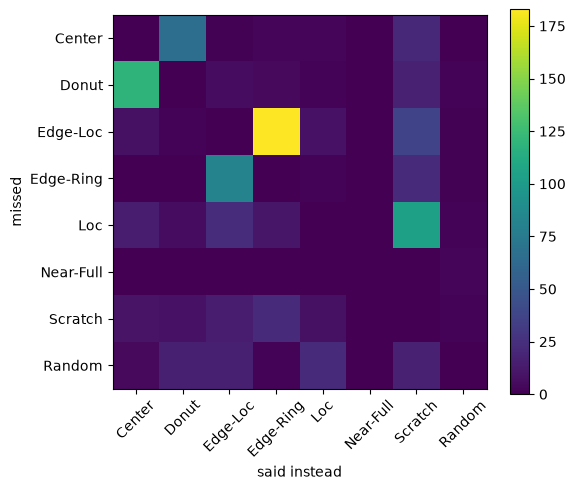

In [6]:
# 8x8 of zeros, row = what it missed, column = what it said instead
mixups = np.zeros((8, 8), dtype=int)
for w in range(len(y_test)):
    for i in range(8):
        if y_test[w, i] == 1 and y_pred[w, i] == 0:        # missed i
            for j in range(8):
                if y_test[w, j] == 0 and y_pred[w, j] == 1:  # added j
                    mixups[i, j] += 1

plt.figure(figsize=(6, 5))
# imshow turns the numbers into colours. the colours are matplotlib's default (viridis), purple low yellow high
plt.imshow(mixups)
plt.colorbar() # the bar on the side that says which colour is which number
plt.xticks(range(8), wafer.DEFECTS, rotation=45)
plt.yticks(range(8), wafer.DEFECTS)
plt.xlabel("said instead")
plt.ylabel("missed")
plt.tight_layout()
plt.show()

## 6. Some wafers it gets wrong

Wrong: 1,878 of 5,534 test wafers


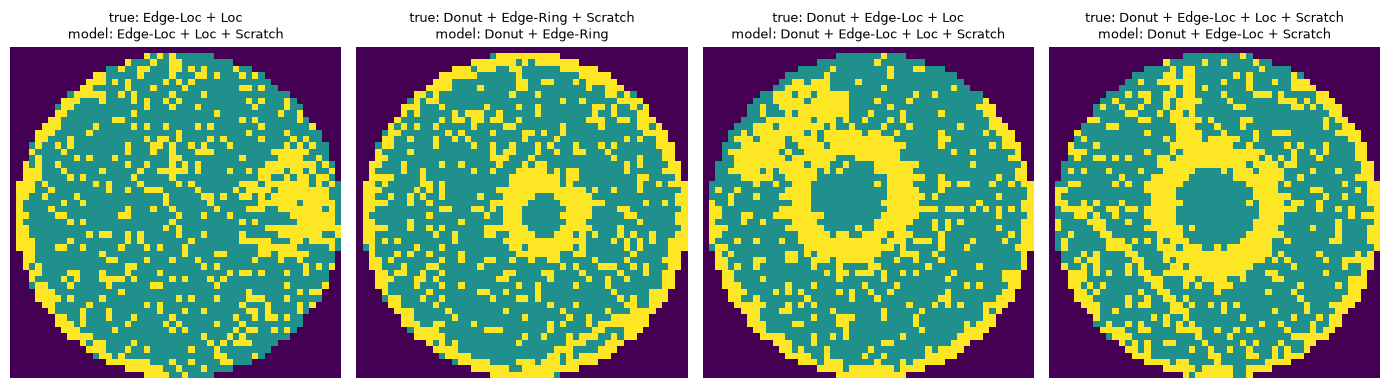

In [7]:
# get the wafers it got wrong
# != gives True where an answer is wrong, any(axis=1) = is anything wrong on that wafer (axis 1 is the row)
# np.where gives back the positions, but in a tuple so you need the [0]
wrong = np.where((y_pred != y_test).any(axis=1))[0]
print(f"Wrong: {len(wrong):,} of {len(y_test):,} test wafers")

plt.figure(figsize=(14, 4))
for k in range(4):
    i = wrong[k * 50]   # spread out, so they aren't all the same type
    plt.subplot(1, 4, k + 1) # 1 row 4 pics, starts counting at 1 not 0
    plt.imshow(maps_test[i])
    plt.title(f"true: {wafer.label_name(y_test[i])}\nmodel: {wafer.label_name(y_pred[i])}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

**What to look for:** is the model missing a defect, or adding one? Can I see the defect myself?

In [8]:
# 07, 08 and 09 read these
np.savez_compressed("output/test_predictions.npz", y_test=y_test, y_pred=y_pred, y_base=y_base)